# SortIQ: Low-Cost Teachable Vision-Guided Sorting System

Camera photo of one object → MobileNetV2 embedding → compare with a library of labelled examples → send **'A'**, **'B'** or **'R'** (review) to the Arduino.

- **Teachable:** a new class is learned from a few camera photos, with no retraining.
- **Confidence-aware:** uncertain or unknown objects go to the review bin ('R').
- **Reconfigurable:** change `TASK_NAME` and `BIN_MAP` in the config cell; the hardware stays the same.

## 1. Install

Run once. Restart the kernel only if this cell installed or upgraded `torch`, `torchvision` or `opencv-python`; a fresh `pyserial` install needs no restart.

In [1]:
%pip install -q pyserial opencv-python torch torchvision datasets numpy pandas matplotlib

Note: you may need to restart the kernel to use updated packages.


## 2. Imports

In [2]:
import os
import csv
import json
import time
import shutil
import tempfile
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import torch
import torch.nn as nn
from torchvision import models
from PIL import Image
from datasets import load_dataset

## 3. Embedder

MobileNetV2 (ImageNet) with its last layer removed, so it outputs 1,280 visual features instead of ImageNet class names. It is **never retrained**.

**Normalisation and cosine similarity.** MobileNetV2 converts an image into a vector of 1,280 numbers that represent its visual features. Take a simple two-number vector:

- **Vector:** A = [3, 4], with length √(3² + 4²) = √25 = 5.
- **Normalising:** divide every number by the length, so the new vector has length 1 but the same direction. Normalised A = [3/5, 4/5] = [0.6, 0.8], and √(0.36 + 0.64) = 1.
- **Cosine similarity:** (A · B) / (length of A × length of B). After normalisation both lengths are 1, so cosine similarity = A · B.

So the dot product of two normalised vectors directly gives their cosine similarity, which SortIQ uses to compare a new image with stored examples.

In [3]:
# Load the pre-trained model only once (re-running this cell does not reload it)
if "feature_extractor" not in globals():
    weights = models.MobileNet_V2_Weights.DEFAULT
    mobilenet = models.mobilenet_v2(weights=weights)
    # Keep everything except the last layer: convolution layers -> average pooling -> flatten
    feature_extractor = nn.Sequential(mobilenet.features, nn.AdaptiveAvgPool2d((1, 1)), nn.Flatten())
    feature_extractor.eval()            # we only use the network, we never train it
    preprocess = weights.transforms()   # resize, crop to 224x224, normalise colours
    print("MobileNetV2 loaded")
else:
    print("MobileNetV2 already loaded")


def get_embedding(image):
    # Accepts a file path, a PIL image or a camera frame (BGR numpy array)
    try:
        if isinstance(image, str):
            image = Image.open(image)
        elif isinstance(image, np.ndarray):
            image = Image.fromarray(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
        if image.mode == "P":
            image = image.convert("RGBA")
        image = image.convert("RGB")
    except Exception as error:
        print("Could not read image:", error)
        return None

    if image.width < 32 or image.height < 32:   # too small to show an object
        return None

    with torch.no_grad():
        feature = feature_extractor(preprocess(image).unsqueeze(0)).squeeze(0).numpy()

    # Normalise so the dot product equals cosine similarity
    length = np.linalg.norm(feature)
    if length == 0:
        return None
    return feature / length

MobileNetV2 loaded


## 4. How K, THRESHOLD and MARGIN were chosen

These experiments (TrashBusters waste photos, CPU, about 3 minutes) produce the values used in the config cell (section 5): `K = 3`, `THRESHOLD = 0.55`, `MARGIN = 0.03`. They do not change the library.

### 4.1 Data and splits

1,000 TrashBusters photos → **640 memory / 160 validation / 200 test**, no overlap.

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# Load the first 1,000 training images of the TrashBusters dataset (cached after the first download)
dataset = load_dataset("TrashBusters/combined", split="train[:1000]")

labels = np.array(dataset["label"])
label_names = list(dataset.features["label"].names)   # a normal Python list, so new categories can be added later

print("Images loaded:", len(dataset))
for label_id in range(len(label_names)):
    print(f"  {label_id} = {label_names[label_id]:<10} {np.sum(labels == label_id)} images")

Images loaded: 1000
  0 = cardboard  160 images
  1 = glass      188 images
  2 = metal      157 images
  3 = paper      150 images
  4 = plastic    168 images
  5 = trash      177 images


In [5]:
# Keep 20% aside as the final test set
all_idx = np.arange(len(dataset))
reference_idx, test_idx = train_test_split(
    all_idx, test_size=0.20, random_state=42, stratify=labels
)

# From the remaining 800, keep 20% for validation
memory_idx, val_idx = train_test_split(
    reference_idx, test_size=0.20, random_state=21, stratify=labels[reference_idx]
)

print("Memory (reference examples):", len(memory_idx))
print("Validation images:", len(val_idx))
print("Test images:", len(test_idx))

# Safety check: no image may appear in two splits
print("Shared images memory/val, memory/test, val/test:",
      len(set(memory_idx) & set(val_idx)),
      len(set(memory_idx) & set(test_idx)),
      len(set(val_idx) & set(test_idx)))

Memory (reference examples): 640
Validation images: 160
Test images: 200
Shared images memory/val, memory/test, val/test: 0 0 0


### 4.2 Embeddings of the 1,000 photos

Computed once with the same `get_embedding` as the live system.

In [6]:
if "embeddings" not in globals():
    # Compute the embedding of every image ONCE; all later steps reuse these vectors
    embeddings = []
    for i in range(len(dataset)):
        embeddings.append(get_embedding(dataset[i]["image"]))
        if (i + 1) % 250 == 0:
            print(f"Processed {i + 1}/{len(dataset)} images")

    bad_images = 0
    for vector in embeddings:
        if vector is None:
            bad_images += 1
    print("Unusable images:", bad_images)

    embeddings = np.array(embeddings)

    # The memory = embeddings of the 640 memory images + their category numbers
    memory_embeddings = embeddings[memory_idx]
    memory_labels = labels[memory_idx]

    print("All embeddings:", embeddings.shape)
    print("Memory:", memory_embeddings.shape, "| labels:", memory_labels.shape)
else:
    print("Already computed, skipped")
memory_embeddings = embeddings[memory_idx]
memory_labels = labels[memory_idx]

Processed 250/1000 images


Processed 500/1000 images


Processed 750/1000 images


Processed 1000/1000 images
Unusable images: 0
All embeddings: (1000, 1280)
Memory: (640, 1280) | labels: (640,)


## Best single match
1.For all val images Compare it with all stored reference images.
2.Find the single closest reference image.
3.Check whether that reference image's category matches the actual category.
4.If matches increase correct by 1

In [7]:
# One validation image: compare it with all 640 memory images
query = embeddings[val_idx[1]]
similarities = memory_embeddings @ query
best_row = np.argmax(similarities)

print("True category:            ", label_names[labels[val_idx[1]]])
print("Closest memory example is:", label_names[memory_labels[best_row]],
      "| similarity", round(float(similarities[best_row]), 3))

# Repeat for every validation image
correct = 0
for i in val_idx:
    similarities = memory_embeddings @ embeddings[i]
    if memory_labels[np.argmax(similarities)] == labels[i]:
        correct += 1
print(f"\nBest single match, validation accuracy: {correct}/{len(val_idx)} = {correct / len(val_idx) * 100:.2f}%")

True category:             trash
Closest memory example is: plastic | similarity 0.515

Best single match, validation accuracy: 121/160 = 75.62%


Best single match: **75.62%** validation accuracy.

### 4.3 Top-k score and the choice of K

Score of a category = average similarity of its k closest examples; the highest score wins.

In [8]:
def category_scores(query, memory_embeddings, memory_labels, k=3):
    # Cosine similarity between the new image and every stored example
    similarities = memory_embeddings @ query

    scores = {}
    for label_id in np.unique(memory_labels):
        # Find the most similar examples for each category
        class_similarities = np.sort(similarities[memory_labels == label_id])[::-1]
        scores[int(label_id)] = float(np.mean(class_similarities[:k]))
    return scores


def predict_category(query, memory_embeddings, memory_labels, k=3):
    # The category with the highest top-k score (no rejection yet)
    scores = category_scores(query, memory_embeddings, memory_labels, k)
    return max(scores, key=scores.get)


# Example: scores of every category for one validation image
scores = category_scores(embeddings[val_idx[1]], memory_embeddings, memory_labels, k=3)
print("True category:", label_names[labels[val_idx[1]]])
for label_id in scores:
    print(f"  {label_names[label_id]:<10} top-3 score {scores[label_id]:.3f}")

True category: trash
  cardboard  top-3 score 0.336
  glass      top-3 score 0.390
  metal      top-3 score 0.279
  paper      top-3 score 0.303
  plastic    top-3 score 0.391
  trash      top-3 score 0.409


In [9]:
# Choose k using the VALIDATION set only
val_actual = labels[val_idx]

for k in [1, 3, 5, 10]:
    predictions = []
    for i in val_idx:
        predictions.append(predict_category(embeddings[i], memory_embeddings, memory_labels, k))
    print(f"Top-{k} score, validation accuracy: {accuracy_score(val_actual, predictions) * 100:.2f}%")

Top-1 score, validation accuracy: 75.62%


Top-3 score, validation accuracy: 77.50%
Top-5 score, validation accuracy: 76.88%


Top-10 score, validation accuracy: 71.88%


**k = 3 is best** (77.50% vs 75.62% for the single best match, 76.88% for k = 5, 71.88% for k = 10).

### 4.4 Bigger memory (3,520 examples) confirms K

4,000 more photos: 3,000 extra memory and 1,000 extra validation. Near-duplicates of validation/test photos are removed from memory.

In [10]:
if "extra_embeddings" not in globals():
    # Load 4,000 more training images that were not used anywhere yet
    extra_dataset = load_dataset("TrashBusters/combined", split="train[1000:5000]")
    extra_labels = np.array(extra_dataset["label"])

    extra_embeddings = []
    for i in range(len(extra_dataset)):
        extra_embeddings.append(get_embedding(extra_dataset[i]["image"]))
        if (i + 1) % 1000 == 0:
            print(f"Processed {i + 1}/{len(extra_dataset)} extra images")
    extra_embeddings = np.array(extra_embeddings)

    # First 3,000 -> extra memory examples, last 1,000 -> extra validation images
    extra_memory_idx = np.arange(0, 3000)
    extra_val_idx = np.arange(3000, 4000)
    print("Extra embeddings:", extra_embeddings.shape)
else:
    print("Already computed, skipped")

Processed 1000/4000 extra images


Processed 2000/4000 extra images


Processed 3000/4000 extra images


Processed 4000/4000 extra images
Extra embeddings: (4000, 1280)


In [11]:
# Extended validation set = original 160 + 1,000 extra images
val_embeddings = np.concatenate([embeddings[val_idx], extra_embeddings[extra_val_idx]])
val_labels = np.concatenate([labels[val_idx], extra_labels[extra_val_idx]])

# Candidate memory = original 640 + 3,000 extra images
candidate_embeddings = np.concatenate([memory_embeddings, extra_embeddings[extra_memory_idx]])
candidate_labels = np.concatenate([memory_labels, extra_labels[extra_memory_idx]])

# The combined dataset contains near-identical copies of some photos.
# Drop memory candidates that are almost identical (similarity > 0.95) to any validation or test image,
# otherwise SortIQ could simply "remember" a test photo.
held_out_embeddings = np.concatenate([val_embeddings, embeddings[test_idx]])
closest_held_out = (candidate_embeddings @ held_out_embeddings.T).max(axis=1)
keep = closest_held_out < 0.95

final_memory_embeddings = candidate_embeddings[keep]
final_memory_labels = candidate_labels[keep]

print("Near-duplicates removed:", int(np.sum(~keep)))
print("Final memory:", final_memory_embeddings.shape)
print("Extended validation set:", len(val_labels), "images")
for label_id in range(6):
    print(f"  {label_names[label_id]:<10} {np.sum(final_memory_labels == label_id)} memory examples")

Near-duplicates removed: 120
Final memory: (3520, 1280)
Extended validation set: 1160 images
  cardboard  568 memory examples
  glass      619 memory examples
  metal      571 memory examples
  paper      550 memory examples
  plastic    590 memory examples
  trash      622 memory examples


In [12]:
# Compare the 640-example memory with the final memory on the extended validation set
rows = []
for k in [1, 3, 5, 10]:
    small_predictions = []
    final_predictions = []
    for vector in val_embeddings:
        small_predictions.append(predict_category(vector, memory_embeddings, memory_labels, k))
        final_predictions.append(predict_category(vector, final_memory_embeddings, final_memory_labels, k))
    rows.append({"k": k,
                 "640-example memory %": round(accuracy_score(val_labels, small_predictions) * 100, 2),
                 "final memory %": round(accuracy_score(val_labels, final_predictions) * 100, 2)})
print(pd.DataFrame(rows).to_string(index=False))

 k  640-example memory %  final memory %
 1                 75.34           80.60
 3                 77.59           83.36
 5                 77.76           83.45
10                 76.55           82.76


With the bigger memory, k = 3 (83.36%) and k = 5 (83.45%) are tied and both beat the single best match (80.60%), so **K = 3** is kept.

### 4.5 Unknown objects for choosing the threshold

Batteries, e-cigarettes and electronic devices cropped from BowerApp; half for choosing the threshold, half kept for testing.

In [13]:
if "unknown_embeddings" not in globals():
    # Unknown objects: items from BowerApp that are not one of our six categories
    bower = load_dataset("BowerApp/bower-waste-annotations", split="train")
    unknown_types = ["Battery", "E-cigarette", "Electronic Device"]

    unknown_crops = []
    for i, object_name in enumerate(bower["object"]):
        if object_name not in unknown_types:
            continue
        row = bower[i]
        # Skip tiny bounding boxes (object too small to see)
        if row["x2"] - row["x1"] < 40 or row["y2"] - row["y1"] < 40:
            continue
        unknown_crops.append(row["image"].crop((row["x1"], row["y1"], row["x2"], row["y2"])))

    unknown_embeddings = []
    for crop in unknown_crops:
        unknown_embeddings.append(get_embedding(crop))
    unknown_embeddings = np.array(unknown_embeddings)

    # Half for choosing thresholds, half kept for the final test
    unk_val_idx, unk_test_idx = train_test_split(np.arange(len(unknown_crops)), test_size=0.5, random_state=42)
    print("Unknown objects:", len(unknown_crops))
    print("Unknown validation half:", len(unk_val_idx), "| unknown test half:", len(unk_test_idx))
else:
    print("Already computed, skipped")

Unknown objects: 187
Unknown validation half: 93 | unknown test half: 94


### 4.6 Threshold and margin sweep (validation only)

In [14]:
def scores_for_many(vectors, memory_embeddings, memory_labels, k=3):
    # Predicted category, best score and second-best score for many vectors
    predicted, best_scores, second_scores = [], [], []
    for vector in vectors:
        scores = category_scores(vector, memory_embeddings, memory_labels, k)
        ranked = sorted(scores, key=scores.get, reverse=True)
        predicted.append(ranked[0])
        best_scores.append(scores[ranked[0]])
        second_scores.append(scores[ranked[1]])
    return np.array(predicted), np.array(best_scores), np.array(second_scores)


# Try several threshold / margin pairs on VALIDATION data only
val_pred, val_best, val_second = scores_for_many(val_embeddings, final_memory_embeddings, final_memory_labels, k=3)
unk_pred, unk_best, unk_second = scores_for_many(unknown_embeddings[unk_val_idx], final_memory_embeddings, final_memory_labels, k=3)

rows = []
for threshold in [0.45, 0.50, 0.55, 0.60, 0.65, 0.70]:
    for margin_threshold in [0.00, 0.03, 0.05]:
        accepted = (val_best >= threshold) & (val_best - val_second >= margin_threshold)
        unknown_rejected = (unk_best < threshold) | (unk_best - unk_second < margin_threshold)
        wrong = accepted & (val_pred != val_labels)
        rows.append({
            "threshold": threshold,
            "margin": margin_threshold,
            "coverage %": round(accepted.mean() * 100, 1),
            "accepted accuracy %": round((val_pred[accepted] == val_labels[accepted]).mean() * 100, 1),
            "wrong auto-sorts %": round(wrong.mean() * 100, 1),
            "unknowns rejected %": round(unknown_rejected.mean() * 100, 1),
        })

sweep = pd.DataFrame(rows)
print(sweep.to_string(index=False))

 threshold  margin  coverage %  accepted accuracy %  wrong auto-sorts %  unknowns rejected %
      0.45    0.00        96.5                 84.2                15.3                 69.9
      0.45    0.03        79.6                 90.7                 7.4                 83.9
      0.45    0.05        68.5                 95.2                 3.3                 89.2
      0.50    0.00        89.6                 85.4                13.1                 93.5
      0.50    0.03        76.2                 91.1                 6.8                 95.7
      0.50    0.05        66.5                 95.5                 3.0                 97.8
      0.55    0.00        79.7                 87.0                10.3                 98.9
      0.55    0.03        69.7                 92.0                 5.6                 98.9
      0.55    0.05        62.2                 96.3                 2.3                 98.9
      0.60    0.00        62.8                 89.6                 6.

In [15]:
# Selection rule (validation only):
#   accepted accuracy >= 90% AND unknown rejection >= 98%, then choose the highest coverage
good = sweep[(sweep["accepted accuracy %"] >= 90) & (sweep["unknowns rejected %"] >= 98)]
chosen = good.sort_values("coverage %", ascending=False).iloc[0]
chosen_threshold = float(chosen["threshold"])
chosen_margin = float(chosen["margin"])

print("Selected threshold:", chosen_threshold)
print("Selected margin:   ", chosen_margin)
print(sweep[(sweep["threshold"] == chosen_threshold) & (sweep["margin"] == chosen_margin)].to_string(index=False))

Selected threshold: 0.55
Selected margin:    0.03
 threshold  margin  coverage %  accepted accuracy %  wrong auto-sorts %  unknowns rejected %
      0.55    0.03        69.7                 92.0                 5.6                 98.9


Selected **threshold 0.55, margin 0.03** (validation: 69.7% sorted automatically, 92.0% of them correct, 98.9% of unknowns rejected). These values are used in the config cell (section 5).

## 5. Config

All settings in one place. `MOCK_SERIAL = True` runs everything without an Arduino (commands are only printed).

In [16]:
MOCK_SERIAL = True          # True = no Arduino needed
TASK_NAME = "waste"         # each task has its own folder, library and log
SERIAL_PORT = "COM3"        # Arduino port (Device Manager -> Ports)
BAUD_RATE = 9600
CAMERA_INDEX = 1            # USB webcam is usually 1 (0 = laptop camera)

# Which class goes to which gate. Classes not listed here are sent to 'R'.
BIN_MAP = {"metal": "A", "plastic": "B"}

# Classifier
THRESHOLD = 0.55            # minimum top-3 similarity to sort automatically (chosen in section 4.6)
MARGIN = 0.03               # minimum gap between the best and second-best class (section 4.6)
K = 3                       # closest examples averaged per class (chosen in sections 4.3-4.4)
MIN_EXAMPLES = 3            # a class needs this many examples before it can be sorted

# Teaching rules
EXAMPLES_PER_TEACH = 5      # photos captured by teach()
DUPLICATE_THRESHOLD = 0.98  # an example this similar to a stored one is a duplicate
MAX_EXAMPLES_PER_CLASS = 20

PRELOAD_WASTE = True        # start the library with the 6 TrashBusters waste classes
ROI = (160, 80, 320, 320)   # x, y, width, height of the box that is classified

# Folders (created automatically)
TASK_DIR = os.path.join("tasks", TASK_NAME)
LIBRARY_FILE = os.path.join(TASK_DIR, "library.npz")
REVIEW_DIR = os.path.join(TASK_DIR, "review_images")
PROMOTED_DIR = os.path.join(REVIEW_DIR, "promoted")
PROMOTED_FILE = os.path.join(TASK_DIR, "promoted.json")
LOG_FILE = os.path.join(TASK_DIR, "log.csv")
RESULTS_DIR = os.path.join(TASK_DIR, "results")
DATASET_DIR = "dataset"     # dataset/<class_name>/*.jpg and dataset/unknown/*.jpg

for folder in [TASK_DIR, REVIEW_DIR, PROMOTED_DIR, RESULTS_DIR]:
    os.makedirs(folder, exist_ok=True)
print("Task folder:", TASK_DIR)

Task folder: tasks\waste


## 6. Library (add / remove rules)

The library is a dictionary `{class name: array of example embeddings}`, saved as `library.npz` in the task folder.
- Labels are trimmed and lower-cased, so "Bolt " and "bolt" are the same class.
- Every function returns a status: `ADDED`, `ALREADY_EXISTS`, `DUPLICATE_SKIPPED`, `CLASS_FULL`, `NOT_FOUND`, `REMOVED`, `CANCELLED` or `ALREADY_PROMOTED`.

In [17]:
ADDED = "ADDED"
ALREADY_EXISTS = "ALREADY_EXISTS"
DUPLICATE_SKIPPED = "DUPLICATE_SKIPPED"
CLASS_FULL = "CLASS_FULL"
NOT_FOUND = "NOT_FOUND"
REMOVED = "REMOVED"
CANCELLED = "CANCELLED"
ALREADY_PROMOTED = "ALREADY_PROMOTED"


def clean_label(label):
    return label.strip().lower()


def load_library(path):
    library = {}
    if os.path.exists(path):
        data = np.load(path)
        for label in data.files:
            library[label] = data[label]
    return library


def save_library(library, path):
    np.savez(path, **library)


def create_class(library, label):
    label = clean_label(label)
    if label in library:
        return ALREADY_EXISTS
    library[label] = np.zeros((0, 1280))
    return ADDED


def add_example(library, label, vector):
    label = clean_label(label)
    if label not in library:
        return NOT_FOUND
    examples = library[label]
    if len(examples) >= MAX_EXAMPLES_PER_CLASS:
        return CLASS_FULL
    # Skip the example if it is almost identical to one already stored
    if len(examples) > 0 and np.max(examples @ vector) > DUPLICATE_THRESHOLD:
        return DUPLICATE_SKIPPED
    library[label] = np.vstack([examples, vector])
    return ADDED


def remove_class(library, label):
    label = clean_label(label)
    if label not in library:
        return NOT_FOUND
    del library[label]          # other classes are not touched
    return REMOVED


# Load the library of this task (only again if TASK_NAME changed)
if "library" not in globals() or library_task != TASK_NAME:
    library = load_library(LIBRARY_FILE)
    library_task = TASK_NAME
print("Classes in library:", {label: len(library[label]) for label in library})

Classes in library: {'cardboard': 20, 'glass': 20, 'metal': 20, 'paper': 20, 'plastic': 20, 'trash': 20}


## 7. Pre-load the 6 waste classes

Adds up to `MAX_EXAMPLES_PER_CLASS` TrashBusters photos per waste class, following the same add rules. Classes that already exist are skipped, so re-running changes nothing.

In [18]:
if PRELOAD_WASTE:
    waste = load_dataset("TrashBusters/combined", split="train[:1000]")
    waste_labels = np.array(waste["label"])
    changed = False

    for label_id, name in enumerate(waste.features["label"].names):
        if create_class(library, name) == ALREADY_EXISTS:
            print(f"'{name}' already in library ({len(library[name])} examples), skipped")
            continue
        changed = True
        for i in np.where(waste_labels == label_id)[0]:
            if len(library[name]) >= MAX_EXAMPLES_PER_CLASS:
                break
            vector = get_embedding(waste[int(i)]["image"])
            if vector is not None:
                add_example(library, name, vector)
        print(f"'{name}' added with {len(library[name])} examples")

    # Save only when something changed
    if changed:
        save_library(library, LIBRARY_FILE)
        print("Library saved")

'cardboard' already in library (20 examples), skipped
'glass' already in library (20 examples), skipped
'metal' already in library (20 examples), skipped
'paper' already in library (20 examples), skipped
'plastic' already in library (20 examples), skipped
'trash' already in library (20 examples), skipped


## 8. Classifier and bin mapping

- **Class score:** the average similarity of the class's `K` closest examples.
- **Confidence check:** the object is only sorted if the best score ≥ `THRESHOLD`, it beats the second-best class by ≥ `MARGIN`, and the class has ≥ `MIN_EXAMPLES` examples. Otherwise it goes to **REVIEW**.
- **Bin mapping:** `BIN_MAP` turns the decision into 'A' or 'B'; review and unmapped classes become 'R'.

In [19]:
def classify(vector, library):
    # Top-K average similarity for every class
    scores = {}
    for label in library:
        if len(library[label]) > 0:
            similarities = np.sort(library[label] @ vector)[::-1]
            scores[label] = float(np.mean(similarities[:K]))
    if len(scores) == 0:
        return {"decision": "REVIEW", "label": None, "score": 0.0, "margin": 0.0, "reason": "library is empty"}

    ranked = sorted(scores, key=scores.get, reverse=True)
    best = ranked[0]
    second_score = scores[ranked[1]] if len(ranked) > 1 else 0.0
    margin = scores[best] - second_score
    result = {"decision": "REVIEW", "label": best, "score": scores[best], "margin": margin}

    # Send uncertain objects to review instead of guessing
    if scores[best] < THRESHOLD:
        result["reason"] = f"similarity {scores[best]:.2f} < {THRESHOLD}"
    elif margin < MARGIN:
        result["reason"] = f"too close to '{ranked[1]}' (margin {margin:.2f} < {MARGIN})"
    elif len(library[best]) < MIN_EXAMPLES:
        result["reason"] = f"'{best}' has only {len(library[best])} examples"
    else:
        result["decision"] = best
        result["reason"] = f"confident (margin {margin:.2f})"
    return result


warned_labels = set()

def get_command(decision):
    # 'A' or 'B' from BIN_MAP; review and unmapped classes go to 'R'
    if decision == "REVIEW":
        return "R"
    if decision not in BIN_MAP:
        if decision not in warned_labels:
            print(f"Warning: '{decision}' has no entry in BIN_MAP, sending 'R'. Add it to BIN_MAP to sort it.")
            warned_labels.add(decision)
        return "R"
    return BIN_MAP[decision]


# Check BIN_MAP once
for label in BIN_MAP:
    if BIN_MAP[label] not in ("A", "B"):
        print(f"Warning: BIN_MAP['{label}'] must be 'A' or 'B'")
    if label not in library:
        print(f"Warning: '{label}' is in BIN_MAP but not in the library")
print("Bins:", BIN_MAP, "| everything else -> 'R'")

Bins: {'metal': 'A', 'plastic': 'B'} | everything else -> 'R'


## 9. Serial link (real or mock)

Sends exactly one character, 'A', 'B' or 'R', at 9600 baud. A reply from the Arduino is printed only if one is already waiting (non-blocking). If the port cannot be opened, the notebook falls back to mock mode.

In [20]:
if "serial_port" not in globals():
    serial_port = None


def open_serial():
    global serial_port
    if MOCK_SERIAL:
        print("Mock serial: commands are only printed")
        return
    if serial_port is not None and serial_port.is_open:
        print("Serial port already open")
        return
    try:
        import serial
        serial_port = serial.Serial(SERIAL_PORT, BAUD_RATE, timeout=0)
        time.sleep(2)               # the Arduino restarts when the port opens
        print("Connected to", SERIAL_PORT)
    except Exception as error:
        serial_port = None
        print(f"Could not open {SERIAL_PORT} ({error}). Using mock mode.")


def send_command(command):
    if command not in ("A", "B", "R"):
        print("Invalid command:", command)
        return
    if serial_port is None:
        print(f"[MOCK] sent '{command}'")
        return
    serial_port.write(command.encode("ascii"))
    if serial_port.in_waiting > 0:
        print("Arduino:", serial_port.read(serial_port.in_waiting).decode(errors="ignore").strip())


open_serial()

Mock serial: commands are only printed


## 10. Camera

Opens the camera once and reuses it. `grab_roi()` returns the full frame and the ROI crop that is classified.

In [21]:
if "cap" not in globals():
    cap = None


def open_camera():
    global cap
    if cap is not None and cap.isOpened():
        return True
    cap = cv2.VideoCapture(CAMERA_INDEX, cv2.CAP_DSHOW)
    if not cap.isOpened():
        print(f"Camera {CAMERA_INDEX} not found. Check CAMERA_INDEX in the config cell.")
        cap = None
        return False
    return True


def grab_roi():
    if not open_camera():
        return None, None
    for _ in range(3):              # skip old buffered frames
        cap.grab()
    ok, frame = cap.read()
    if not ok:
        print("Could not read a frame from the camera")
        return None, None
    x, y, w, h = ROI
    return frame, frame[y:y + h, x:x + w]

## 11. Actions: classify, sort, teach, delete, promote

Plain functions that also work without the live window:
- **Classify and sort:** `classify_once()`, `sort_once()`
- **Library:** `teach("bolt")`, `delete_class("bolt")`, `list_classes()`
- **Review images:** `list_review_images()`, `promote("file.jpg", "bolt")`

`sort_once()` sends the command, writes a line to `log.csv`, and saves uncertain objects to `review_images/`.

In [22]:
def log_result(result):
    new_file = not os.path.exists(LOG_FILE)
    with open(LOG_FILE, "a", newline="") as file:
        writer = csv.writer(file)
        if new_file:
            writer.writerow(["time", "decision", "best_label", "score", "margin", "command", "latency_ms"])
        writer.writerow([datetime.now().isoformat(timespec="seconds"), result["decision"], result["label"],
                         round(result["score"], 4), round(result["margin"], 4), result["command"],
                         round(result["latency_ms"], 1)])


def classify_once(show=True):
    frame, crop = grab_roi()
    if crop is None:
        return None
    start = time.time()
    vector = get_embedding(crop)
    if vector is None:
        result = {"decision": "REVIEW", "label": None, "score": 0.0, "margin": 0.0, "reason": "unusable image"}
    else:
        result = classify(vector, library)
    result["latency_ms"] = (time.time() - start) * 1000
    result["command"] = get_command(result["decision"])
    result["crop"] = crop
    if show:
        print(f"{result['decision']} -> '{result['command']}' | best: {result['label']} "
              f"({result['score']:.2f}, margin {result['margin']:.2f}) | {result['reason']} | {result['latency_ms']:.0f} ms")
    return result


def sort_once():
    result = classify_once()
    if result is None:
        return None
    send_command(result["command"])
    log_result(result)
    # Keep uncertain objects so they can be promoted to a class later
    if result["decision"] == "REVIEW":
        filename = datetime.now().strftime("%Y%m%d_%H%M%S_%f") + ".jpg"
        cv2.imwrite(os.path.join(REVIEW_DIR, filename), result["crop"])
        print("Saved review image:", filename)
    return result


def teach(label, n=EXAMPLES_PER_TEACH):
    label = clean_label(label)
    if label in library:
        print(f"Class '{label}' already exists with {len(library[label])} examples. No changes made. "
              f"To replace it, delete it first ('d') and teach it again.")
        return ALREADY_EXISTS
    if not open_camera():
        return CANCELLED

    create_class(library, label)
    while len(library[label]) < n:
        answer = input(f"[{label}] example {len(library[label]) + 1}/{n}: place the object and press Enter (q = stop) ")
        if answer.strip().lower() == "q":
            break
        frame, crop = grab_roi()
        vector = get_embedding(crop) if crop is not None else None
        if vector is None:
            print("No usable image, try again")
            continue
        status = add_example(library, label, vector)
        if status == DUPLICATE_SKIPPED:
            print("Duplicate example skipped")
        elif status == CLASS_FULL:
            print(f"Class '{label}' is full ({MAX_EXAMPLES_PER_CLASS} examples)")
            break
        else:
            print("Example stored")

    if len(library[label]) == 0:       # nothing stored: do not keep an empty class
        remove_class(library, label)
        print("No examples stored, class not created")
        return CANCELLED
    save_library(library, LIBRARY_FILE)
    print(f"Class '{label}' taught with {len(library[label])} examples")
    if label not in BIN_MAP:
        print(f"Note: '{label}' is not in BIN_MAP, so it is sent to 'R' until you add it there.")
    return ADDED


def delete_class(label):
    label = clean_label(label)
    if label not in library:
        print(f"Class '{label}' not found. Nothing to delete.")
        return NOT_FOUND
    if input(f"Delete class '{label}' ({len(library[label])} examples)? (y/n) ").strip().lower() != "y":
        print("Cancelled, nothing changed")
        return CANCELLED
    remove_class(library, label)
    save_library(library, LIBRARY_FILE)
    print(f"Class '{label}' deleted")
    return REMOVED


def promote_image(library, filename, label, review_dir, promoted_file):
    # Add one review image to an existing class (core rules, no printing or saving)
    label = clean_label(label)
    promoted = []
    if os.path.exists(promoted_file):
        with open(promoted_file) as file:
            promoted = json.load(file)
    if filename in promoted:
        return ALREADY_PROMOTED
    if label not in library:
        return NOT_FOUND
    path = os.path.join(review_dir, filename)
    vector = get_embedding(path) if os.path.exists(path) else None
    if vector is None:
        return NOT_FOUND
    status = add_example(library, label, vector)
    if status == ADDED:
        promoted.append(filename)
        with open(promoted_file, "w") as file:
            json.dump(promoted, file)
        os.makedirs(os.path.join(review_dir, "promoted"), exist_ok=True)
        shutil.move(path, os.path.join(review_dir, "promoted", filename))
    return status


def promote(filename, label):
    status = promote_image(library, filename, label, REVIEW_DIR, PROMOTED_FILE)
    messages = {ADDED: f"Promoted '{filename}' to '{clean_label(label)}'",
                ALREADY_PROMOTED: f"'{filename}' was already promoted. Nothing changed.",
                DUPLICATE_SKIPPED: "Duplicate example skipped",
                CLASS_FULL: f"Class '{clean_label(label)}' is full",
                NOT_FOUND: "Class or image not found. Teach the class first and check the filename."}
    print(messages[status])
    if status == ADDED:
        save_library(library, LIBRARY_FILE)
    return status


def list_classes():
    for label in library:
        print(f"  {label:<12} {len(library[label]):>3} examples -> '{BIN_MAP.get(label, 'R')}'")


def list_review_images():
    files = [f for f in sorted(os.listdir(REVIEW_DIR)) if f.endswith(".jpg")]
    print(f"{len(files)} review images:", files)
    return files


list_classes()

  cardboard     20 examples -> 'R'
  glass         20 examples -> 'R'
  metal         20 examples -> 'A'
  paper         20 examples -> 'R'
  plastic       20 examples -> 'B'
  trash         20 examples -> 'R'


## 12. Live preview (keys)

Opens a camera window with the green ROI box. Keys while the window is focused:
- **c** classify, **s** sort (send command)
- **t** teach, **d** delete, **p** promote (each asks for input in the notebook)
- **l** list classes, **q** quit

The camera is always released when the window closes, even after an error.

In [23]:
def live_preview():
    if not open_camera():
        return
    status_text = "c=classify s=sort t=teach l=list d=delete p=promote q=quit"
    try:
        while True:
            ok, frame = cap.read()
            if not ok:
                print("Could not read a frame from the camera")
                break
            x, y, w, h = ROI
            shown = frame.copy()
            cv2.rectangle(shown, (x, y), (x + w, y + h), (0, 255, 0), 2)
            cv2.putText(shown, status_text, (10, 25), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 255), 2)
            cv2.imshow("SortIQ", shown)

            key = cv2.waitKey(30) & 0xFF
            if key == ord("q"):
                break
            elif key == ord("c") or key == ord("s"):
                result = classify_once() if key == ord("c") else sort_once()
                if result is not None:
                    status_text = f"{result['decision']} -> '{result['command']}' ({result['score']:.2f})"
            elif key == ord("t"):
                teach(input("Label to teach: "))
            elif key == ord("l"):
                list_classes()
            elif key == ord("d"):
                delete_class(input("Label to delete: "))
            elif key == ord("p"):
                list_review_images()
                promote(input("Review image filename: "), input("Class label: "))
    finally:
        cap.release()
        cv2.destroyAllWindows()


live_preview()

Camera 1 not found. Check CAMERA_INDEX in the config cell.


## 13. Cleanup

Releases the camera and the serial port. Run this before unplugging anything or if the webcam stays locked.

In [24]:
if cap is not None:
    cap.release()
    cap = None
cv2.destroyAllWindows()
if serial_port is not None:
    serial_port.close()
    serial_port = None
print("Camera and serial port released")

Camera and serial port released


## 14. Tests (add / remove rules)

Uses fake vectors and a temporary library, so the real library is not touched.

In [25]:
def fake_vector(seed):
    vector = np.random.RandomState(seed).randn(1280)
    return vector / np.linalg.norm(vector)


def check(name, condition):
    print("PASS" if condition else "FAIL", "-", name)


test_library = {}
check("add new class", create_class(test_library, "Bolt ") == ADDED and "bolt" in test_library)
check("add existing class (same label, other case/spaces)", create_class(test_library, "BOLT") == ALREADY_EXISTS)
check("add new example", add_example(test_library, "bolt", fake_vector(1)) == ADDED)
check("add duplicate example", add_example(test_library, "bolt", fake_vector(1)) == DUPLICATE_SKIPPED
      and len(test_library["bolt"]) == 1)
check("add example to missing class", add_example(test_library, "nut", fake_vector(2)) == NOT_FOUND)

for seed in range(2, 2 + MAX_EXAMPLES_PER_CLASS):
    add_example(test_library, "bolt", fake_vector(seed))
check("class full", len(test_library["bolt"]) == MAX_EXAMPLES_PER_CLASS
      and add_example(test_library, "bolt", fake_vector(999)) == CLASS_FULL)

create_class(test_library, "eraser")
add_example(test_library, "eraser", fake_vector(500))
check("remove existing class", remove_class(test_library, "bolt") == REMOVED and "bolt" not in test_library)
check("remove missing class", remove_class(test_library, "bolt") == NOT_FOUND)
check("removing a class keeps the others", len(test_library["eraser"]) == 1)

# Running each action twice: the second time changes nothing
create_class(test_library, "cap")
check("create class twice", create_class(test_library, "cap") == ALREADY_EXISTS and len(test_library["cap"]) == 0)
add_example(test_library, "cap", fake_vector(600))
check("add same example twice", add_example(test_library, "cap", fake_vector(600)) == DUPLICATE_SKIPPED
      and len(test_library["cap"]) == 1)
remove_class(test_library, "cap")
check("remove class twice", remove_class(test_library, "cap") == NOT_FOUND)

# Promote twice, in a temporary folder
temp_dir = tempfile.mkdtemp()
Image.fromarray(np.random.RandomState(7).randint(0, 255, (120, 120, 3), dtype=np.uint8)).save(os.path.join(temp_dir, "r1.jpg"))
promoted_json = os.path.join(temp_dir, "promoted.json")
first = promote_image(test_library, "r1.jpg", "eraser", temp_dir, promoted_json)
second = promote_image(test_library, "r1.jpg", "eraser", temp_dir, promoted_json)
check("promote new image", first == ADDED and os.path.exists(os.path.join(temp_dir, "promoted", "r1.jpg")))
check("promote same image twice", second == ALREADY_PROMOTED and len(test_library["eraser"]) == 2)
shutil.rmtree(temp_dir)

# Bin mapping
check("review decision -> 'R'", get_command("REVIEW") == "R")
check("unmapped class -> 'R'", get_command("not_in_bin_map") == "R")

PASS - add new class
PASS - add existing class (same label, other case/spaces)
PASS - add new example
PASS - add duplicate example
PASS - add example to missing class
PASS - class full
PASS - remove existing class
PASS - remove missing class
PASS - removing a class keeps the others
PASS - create class twice
PASS - add same example twice
PASS - remove class twice


PASS - promote new image
PASS - promote same image twice
PASS - review decision -> 'R'
PASS - unmapped class -> 'R'


## 15. Evaluation data

Put your own photos in `dataset/<class_name>/*.jpg` and unfamiliar objects in `dataset/unknown/*.jpg`. Do **not** reuse the photos you taught with, or the results will look better than they really are. Results are saved in `tasks/<TASK_NAME>/results/`.

In [26]:
def load_dataset_folder(folder):
    # Returns {class_name: array of embeddings} for dataset/<class_name>/*.jpg
    data = {}
    if not os.path.isdir(folder):
        return data
    for class_name in sorted(os.listdir(folder)):
        class_dir = os.path.join(folder, class_name)
        if not os.path.isdir(class_dir):
            continue
        vectors = []
        for filename in sorted(os.listdir(class_dir)):
            if filename.lower().endswith((".jpg", ".jpeg", ".png")):
                vector = get_embedding(os.path.join(class_dir, filename))
                if vector is not None:
                    vectors.append(vector)
        if len(vectors) > 0:
            data[clean_label(class_name)] = np.array(vectors)
    return data


eval_data = load_dataset_folder(DATASET_DIR)
if len(eval_data) == 0:
    print(f"No images found in '{DATASET_DIR}/'. Add dataset/<class_name>/*.jpg to run the evaluation cells.")
else:
    print({name: len(eval_data[name]) for name in eval_data})

No images found in 'dataset/'. Add dataset/<class_name>/*.jpg to run the evaluation cells.


## 16. Threshold tuning

Classifies the dataset photos with the current library at several thresholds (margin = `MARGIN`). The suggested value is only printed; `THRESHOLD` in the config is not changed.

In [27]:
known_names = [name for name in eval_data if name != "unknown" and name in library]
if len(known_names) == 0:
    print("Need dataset photos of at least one class that is in the library.")
else:
    skipped = [name for name in eval_data if name != "unknown" and name not in library]
    if skipped:
        print("Not in library, skipped:", skipped)

    # Score every photo once
    known_rows, unknown_rows = [], []
    for name in known_names:
        for vector in eval_data[name]:
            result = classify(vector, library)
            known_rows.append((name, result["label"], result["score"], result["margin"], len(library[result["label"]])))
    for vector in eval_data.get("unknown", []):
        result = classify(vector, library)
        unknown_rows.append((result["score"], result["margin"]))

    rows = []
    for threshold in np.round(np.arange(0.30, 0.81, 0.05), 2):
        accepted = correct = 0
        for true_name, best, score, margin, count in known_rows:
            if score >= threshold and margin >= MARGIN and count >= MIN_EXAMPLES:
                accepted += 1
                correct += (best == true_name)
        rejected = sum(1 for score, margin in unknown_rows if score < threshold or margin < MARGIN)
        rows.append({"threshold": threshold,
                     "coverage %": round(accepted / len(known_rows) * 100, 1),
                     "accepted accuracy %": round(correct / accepted * 100, 1) if accepted else None,
                     "unknown rejected %": round(rejected / len(unknown_rows) * 100, 1) if unknown_rows else None})
    tuning = pd.DataFrame(rows)
    display(tuning)

    plt.figure(figsize=(6, 4))
    for column in ["coverage %", "accepted accuracy %", "unknown rejected %"]:
        plt.plot(tuning["threshold"], tuning[column], marker="o", label=column)
    plt.axvline(THRESHOLD, color="gray", linestyle="--", label=f"current {THRESHOLD}")
    plt.xlabel("threshold")
    plt.ylabel("%")
    plt.legend()
    plt.title("Threshold tuning")
    plt.tight_layout()
    plt.savefig(os.path.join(RESULTS_DIR, "threshold_tuning.png"))
    plt.show()
    tuning.to_csv(os.path.join(RESULTS_DIR, "threshold_tuning.csv"), index=False)

    # Suggestion: highest coverage with accepted accuracy >= 90% and (if unknowns exist) >= 98% rejected
    good = tuning[tuning["accepted accuracy %"].fillna(0) >= 90]
    if unknown_rows:
        good = good[good["unknown rejected %"] >= 98]
    if len(good) > 0:
        print("Suggested threshold:", good.sort_values("coverage %", ascending=False).iloc[0]["threshold"])
    else:
        print("No threshold reaches the targets; collect more examples or photos.")

Need dataset photos of at least one class that is in the library.


## 17. Few-shot evaluation

How well can a class be learned from only n photos? For each n, n random photos per class become a temporary library and the remaining photos are tested (5 random repeats). This uses only the dataset photos, not the saved library.

In [28]:
class_names = [name for name in eval_data if name != "unknown"]
if len(class_names) < 2:
    print("Need dataset photos of at least 2 classes.")
else:
    rng = np.random.RandomState(0)
    rows = []
    for n in [1, 3, 5, 10]:
        if any(len(eval_data[name]) <= n for name in class_names):
            print(f"n = {n}: skipped (every class needs more than {n} photos)")
            continue
        for trial in range(5):
            temp_library, test_items = {}, []
            for name in class_names:
                order = rng.permutation(len(eval_data[name]))
                temp_library[name] = eval_data[name][order[:n]]
                for i in order[n:]:
                    test_items.append((name, eval_data[name][i]))

            correct = accepted = accepted_correct = 0
            for true_name, vector in test_items:
                result = classify(vector, temp_library)
                correct += (result["label"] == true_name)
                if result["decision"] != "REVIEW":
                    accepted += 1
                    accepted_correct += (result["decision"] == true_name)
            unknown_rejected = [classify(v, temp_library)["decision"] == "REVIEW" for v in eval_data.get("unknown", [])]
            rows.append({"n": n, "trial": trial,
                         "accuracy %": correct / len(test_items) * 100,
                         "coverage %": accepted / len(test_items) * 100,
                         "accepted accuracy %": accepted_correct / accepted * 100 if accepted else np.nan,
                         "unknown rejected %": np.mean(unknown_rejected) * 100 if unknown_rejected else np.nan})

    if rows:
        few_shot = pd.DataFrame(rows).groupby("n").mean().drop(columns="trial").round(1)
        display(few_shot)
        few_shot.to_csv(os.path.join(RESULTS_DIR, "few_shot.csv"))

        plt.figure(figsize=(6, 4))
        for column in few_shot.columns:
            plt.plot(few_shot.index, few_shot[column], marker="o", label=column)
        plt.xlabel("examples per class (n)")
        plt.ylabel("%")
        plt.legend()
        plt.title("Few-shot evaluation (mean of 5 trials)")
        plt.tight_layout()
        plt.savefig(os.path.join(RESULTS_DIR, "few_shot.png"))
        plt.show()
        print(f"Note: with n < MIN_EXAMPLES ({MIN_EXAMPLES}) every object goes to review by design.")

Need dataset photos of at least 2 classes.


## 18. Latency test

Time for one decision (embedding + classification + bin command) on 30 images: dataset photos if available, otherwise a camera frame or a test image.

Camera 1 not found. Check CAMERA_INDEX in the config cell.
No dataset or camera: using a test image (timing does not depend on the content)


Mean 24 ms | median 24 ms | max 31 ms over 30 images


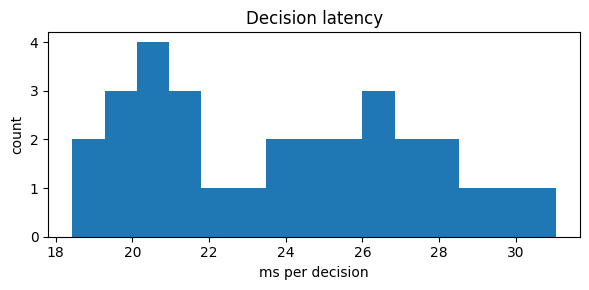

In [29]:
test_images = []
for name in eval_data:
    class_dir = os.path.join(DATASET_DIR, name)
    if os.path.isdir(class_dir):
        for filename in sorted(os.listdir(class_dir)):
            if filename.lower().endswith((".jpg", ".jpeg", ".png")):
                test_images.append(os.path.join(class_dir, filename))
test_images = test_images[:30]
if len(test_images) == 0:
    frame, crop = grab_roi()
    if crop is not None:
        test_images = [crop] * 30
        print("Using a camera frame")
    else:
        test_images = [Image.fromarray(np.random.RandomState(1).randint(0, 255, (320, 320, 3), dtype=np.uint8))] * 30
        print("No dataset or camera: using a test image (timing does not depend on the content)")

times = []
for image in test_images:
    start = time.time()
    vector = get_embedding(image)
    command = get_command(classify(vector, library)["decision"])
    times.append((time.time() - start) * 1000)

latency = pd.DataFrame({"latency_ms": times})
print(f"Mean {np.mean(times):.0f} ms | median {np.median(times):.0f} ms | max {np.max(times):.0f} ms over {len(times)} images")
latency.to_csv(os.path.join(RESULTS_DIR, "latency.csv"), index=False)

plt.figure(figsize=(6, 3))
plt.hist(times, bins=15)
plt.xlabel("ms per decision")
plt.ylabel("count")
plt.title("Decision latency")
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "latency.png"))
plt.show()

## 19. Log analysis

Summary of every `sort_once()` call in `log.csv`: commands sent, review rate, scores and latency.

In [30]:
if not os.path.exists(LOG_FILE):
    print("No log yet. Sort some objects with sort_once() or the 's' key first.")
else:
    log = pd.read_csv(LOG_FILE)
    print(f"Objects sorted: {len(log)} | review rate: {(log['command'] == 'R').mean() * 100:.1f}% | "
          f"mean latency: {log['latency_ms'].mean():.0f} ms")
    summary = log.groupby(["decision", "command"]).size().reset_index(name="count")
    display(summary)
    summary.to_csv(os.path.join(RESULTS_DIR, "log_summary.csv"), index=False)

    fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
    log["command"].value_counts().sort_index().plot(kind="bar", ax=axes[0], title="Commands sent")
    axes[1].hist(log["score"], bins=20)
    axes[1].axvline(THRESHOLD, color="red", linestyle="--", label="threshold")
    axes[1].set_title("Best similarity scores")
    axes[1].legend()
    plt.tight_layout()
    plt.savefig(os.path.join(RESULTS_DIR, "log_analysis.png"))
    plt.show()

No log yet. Sort some objects with sort_once() or the 's' key first.
